# 🚀 Ejercicio Profesional: Sistema de Clasificación y Análisis de Imágenes
## Proyecto Completo de Machine Learning

### 📋 Descripción del Proyecto

**Objetivo:** Desarrollar un sistema completo de clasificación de imágenes que abarque todos los conceptos vistos en clase, desde espacios vectoriales hasta modelos de clasificación.

**Dataset:** dígitos manuscritos *Optical Recognition of Handwritten Digits* (`load_digits` de scikit-learn, versión reducida tipo MNIST): 1797 imágenes de 8×8 píxeles.

**Alcance:**
- Preprocesamiento de datos
- Transformación de variables
- Análisis de espacios vectoriales y distancias
- Reducción de dimensionalidad
- Entrenamiento y evaluación de modelos
- Comparación de técnicas

### 🎯 Objetivos de Aprendizaje

En este proyecto se trabajan los siguientes puntos:

- Aplicar técnicas de preprocesamiento (StandardScaler, MinMaxScaler)
- Transformar variables con One-Hot Encoding y Reshape
- Calcular distancias y similitudes entre vectores
- Reducir dimensionalidad con PCA y t-SNE
- Entrenar y evaluar un MLPClassifier
- Comparar pros y contras de cada técnica
- Construir un pipeline completo de ML

### 🏗️ Estructura del notebook

El notebook integra en un único fichero las siguientes secciones:

1. Espacios vectoriales
2. Distancias y similitud
3. Preprocesamiento
4. Transformación de variables
5. Reducción de dimensionalidad
6. Modelos de clasificación
7. Pipeline completo
8. Comparativa final e informe

---
## 📝 Ejercicio 1: Análisis de Espacios Vectoriales

### Objetivo
Comprender qué son los espacios vectoriales y cómo se representan las imágenes como vectores.

### Tarea
Carga el dataset de dígitos y analiza su estructura como espacio vectorial.

ANÁLISIS DEL ESPACIO VECTORIAL
Número de muestras: 1797
Tamaño de imagen: 8x8 píxeles
Total de características (dimensiones): 64
Número de clases: 10
Clases: [0 1 2 3 4 5 6 7 8 9]


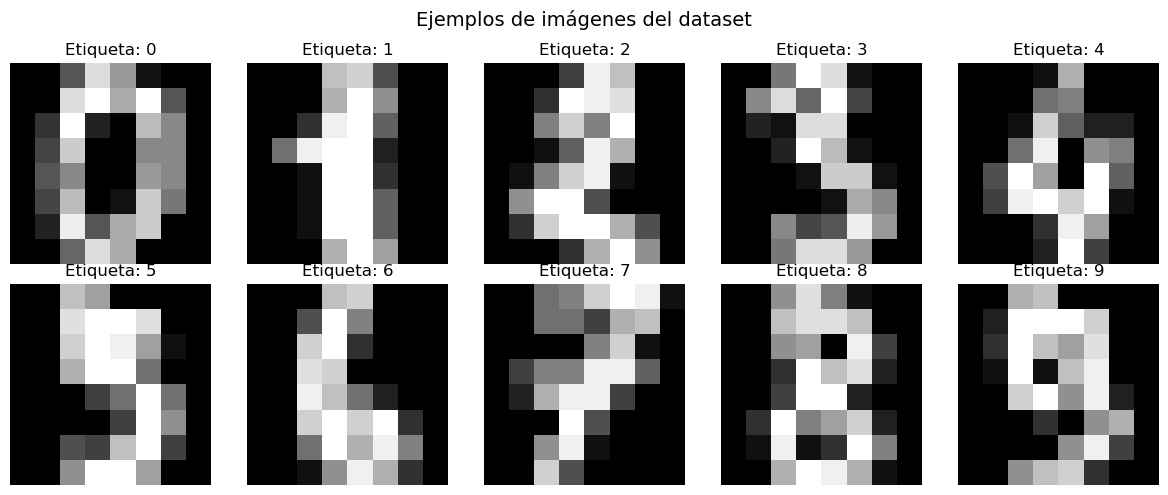

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_digits

digits = load_digits()
X = digits.images
y = digits.target

# Visualizar información básica
print("=" * 60)
print("ANÁLISIS DEL ESPACIO VECTORIAL")
print("=" * 60)
print(f"Número de muestras: {X.shape[0]}")
print(f"Tamaño de imagen: {X.shape[1]}x{X.shape[2]} píxeles")
print(f"Total de características (dimensiones): {X.shape[1] * X.shape[2]}")
print(f"Número de clases: {len(np.unique(y))}")
print(f"Clases: {np.unique(y)}")

# Visualizar algunas imágenes
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X[i], cmap='gray')
    ax.set_title(f'Etiqueta: {y[i]}')
    ax.axis('off')
plt.suptitle('Ejemplos de imágenes del dataset', fontsize=14)
plt.tight_layout()
plt.show()

**Preguntas de Análisis**
1. ¿Cuántas dimensiones tiene cada imagen cuando se aplana? 64
2. ¿Qué representa cada dimensión? Cada dimension representa un pixel en una posicion fija de la imagen
3. ¿Por qué podemos tratar una imagen como un vector? 
Podemos tratar una imagen como un vector porque no es más que una colección ordenada de valores numéricos (la intensidad de cada píxel). Al ordenar sus 64 píxeles en un vector en R64, la imagen se convierte en un punto en un espacio multidimensional, lo que nos permite aplicarle herramientas de álgebra lineal: sumar imágenes, calcular distancias geométricas para medir su similitud y alimentar algoritmos de Machine Learning.
### Ejercicio Práctico

In [2]:
# Tarea 1: Convertir imágenes a vectores
# Cada imagen 8x8 se convierte en un vector de 64 dimensiones

# Método manual
n_samples = X.shape[0]
X_flat = X.reshape(n_samples, -1)

print("ANTES (imagen 8x8):")
print(f"Shape: {X.shape}")
print(f"Ejemplo de imagen[0]:\n{X[0]}")

print("\nDESPUÉS (vector 64):")
print(f"Shape: {X_flat.shape}")
print(f"Ejemplo de vector[0]: {X_flat[0]}")

# Verificar que no se pierde información
X_reconstructed = X_flat.reshape(X.shape)
print(f"\n¿Se puede reconstruir? {np.array_equal(X, X_reconstructed)}")

ANTES (imagen 8x8):
Shape: (1797, 8, 8)
Ejemplo de imagen[0]:
[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]

DESPUÉS (vector 64):
Shape: (1797, 64)
Ejemplo de vector[0]: [ 0.  0.  5. 13.  9.  1.  0.  0.  0.  0. 13. 15. 10. 15.  5.  0.  0.  3.
 15.  2.  0. 11.  8.  0.  0.  4. 12.  0.  0.  8.  8.  0.  0.  5.  8.  0.
  0.  9.  8.  0.  0.  4. 11.  0.  1. 12.  7.  0.  0.  2. 14.  5. 10. 12.
  0.  0.  0.  0.  6. 13. 10.  0.  0.  0.]

¿Se puede reconstruir? True


**Preguntas para Responder**
1. ¿Qué significa que una imagen tenga 64 dimensiones? cada una de esas 64 dimensiones es una variable/eje independiente que mide la intensidad de brillo del píxel en esa posición fija
2. ¿Cómo se relaciona el concepto de "distancia" entre imágenes? Se tiene en cuenta la diferencia de valores entre una imagen u otra. Cuanto mas similar sea el numero mas parecida sera la imagen
3. ¿Qué ventajas tiene representar imágenes como vectores? Incluye ventajas de compatibilidad a la hora de entrenar modelos de Machine Learning, operaciones matematicas u operaciones de dimensionalidad como PCA.

---
## 📝 Ejercicio 2: Distancias y Similitud

### Objetivo
Calcular diferentes tipos de distancias y similitudes entre imágenes (vectores).

### Tarea
Implementar y comparar diferentes métricas de distancia.

ANÁLISIS DE DISTANCIAS Y SIMILITUD


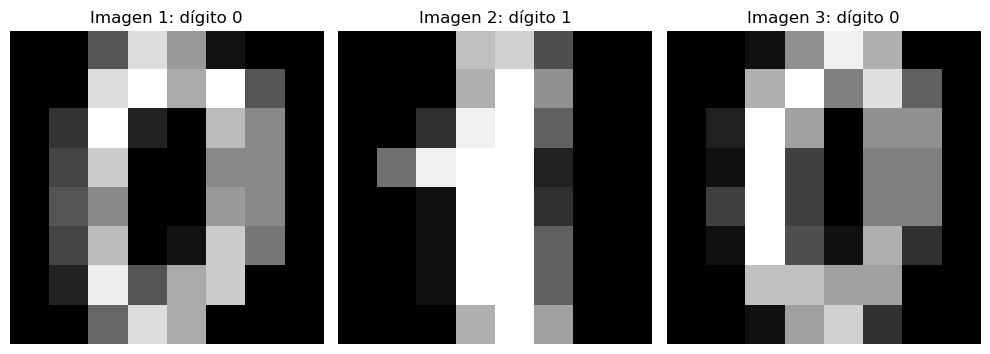

In [3]:
import numpy as np

# Seleccionar algunas imágenes para comparar
img1 = X_flat[0]  # Dígito 0
img2 = X_flat[1]  # Dígito 1
img3 = X_flat[10] # Otro dígito 0

print("=" * 60)
print("ANÁLISIS DE DISTANCIAS Y SIMILITUD")
print("=" * 60)

# Visualizar las imágenes a comparar
fig, axes = plt.subplots(1, 3, figsize=(10, 4))
axes[0].imshow(X[0], cmap='gray')
axes[0].set_title(f'Imagen 1: dígito {y[0]}')
axes[1].imshow(X[1], cmap='gray')
axes[1].set_title(f'Imagen 2: dígito {y[1]}')
axes[2].imshow(X[10], cmap='gray')
axes[2].set_title(f'Imagen 3: dígito {y[10]}')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

### Ejercicio Práctico

In [4]:
# Tarea 2: Calcular diferentes distancias

# 1. Distancia Euclídea, linea recta
dist_euclidean = np.linalg.norm(img1 - img2)
print(f"Distancia Euclídea (img1-img2): {dist_euclidean:.2f}")

# 2. Distancia Manhattan, diferencias absolutas
dist_manhattan = np.sum(np.abs(img1 - img2))
print(f"Distancia Manhattan (img1-img2): {dist_manhattan:.2f}")

# 3. Distancia Hamming (para datos binarizados), elementos diferentes
img1_bin = (img1 > 8).astype(int)  # Binarizar
img2_bin = (img2 > 8).astype(int)
dist_hamming = np.sum(img1_bin != img2_bin) / len(img1_bin)
print(f"Distancia Hamming (img1-img2): {dist_hamming:.4f}")

# 4. Similitud Coseno, angulo entre dos vectores
sim_cosine = np.dot(img1, img2) / (np.linalg.norm(img1) * np.linalg.norm(img2))
print(f"Similitud Coseno (img1-img2): {sim_cosine:.4f}")

# Comparar con imágenes del mismo dígito
print("\n" + "=" * 60)
print("COMPARACIÓN: misma clase vs diferente clase")
print("=" * 60)

# Misma clase (ambos son 0)
dist_misma_clase = np.linalg.norm(img1 - img3)
print(f"Distancia Euclídea (misma clase 0): {dist_misma_clase:.2f}")

# Diferente clase
print(f"Distancia Euclídea (diferente clase): {dist_euclidean:.2f}")

Distancia Euclídea (img1-img2): 59.56
Distancia Manhattan (img1-img2): 335.00
Distancia Hamming (img1-img2): 0.2812
Similitud Coseno (img1-img2): 0.5191

COMPARACIÓN: misma clase vs diferente clase
Distancia Euclídea (misma clase 0): 23.71
Distancia Euclídea (diferente clase): 59.56


### Análisis de Resultados

**Nota sobre el rango de la distancia euclídea:** no es infinita en la práctica. Va desde 0 (imágenes idénticas) hasta un valor máximo acotado por el rango de brillo de los píxeles (en este dataset, máximo teórico de 128, es decir √(64 · 16²)). Cuanto más alto sea el número dentro de ese rango, más diferentes son las imágenes.

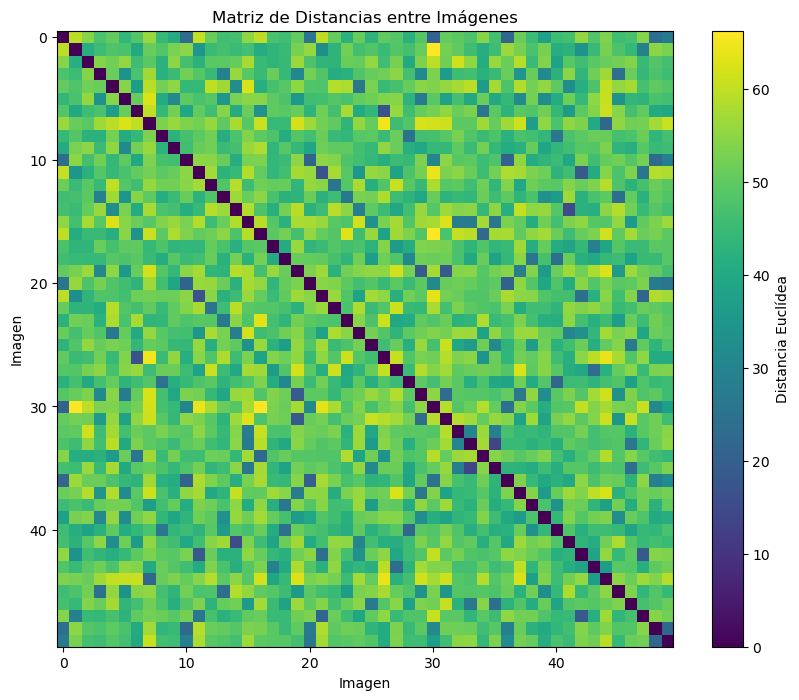


Imágenes más cercanas: (np.int64(33), np.int64(35))
  Distancia: 13.89
  Clases: 5 y 5

Imágenes más lejanas: (np.int64(1), np.int64(30))
  Distancia: 66.28
  Clases: 1 y 0


In [5]:
# Tarea 3: Analizar distancias para múltiples imágenes

# Calcular distancias entre las primeras 50 imágenes
n_compare = 50
dist_matrix = np.zeros((n_compare, n_compare))

for i in range(n_compare):
    for j in range(n_compare):
        dist_matrix[i, j] = np.linalg.norm(X_flat[i] - X_flat[j])

# Visualizar matriz de distancias
plt.figure(figsize=(10, 8))
plt.imshow(dist_matrix, cmap='viridis')
plt.colorbar(label='Distancia Euclídea')
plt.title('Matriz de Distancias entre Imágenes')
plt.xlabel('Imagen')
plt.ylabel('Imagen')
plt.show()

# Encontrar imágenes más cercanas y más lejanas
# La diagonal (distancia de una imagen consigo misma = 0) se marca como NaN para ignorarla.
# Con np.inf el mínimo sale bien, pero argmax devolvería la propia diagonal (inf).
dist_matrix = dist_matrix.astype(float, copy=True)
np.fill_diagonal(dist_matrix, np.nan)
min_idx = np.unravel_index(np.nanargmin(dist_matrix), dist_matrix.shape)
max_idx = np.unravel_index(np.nanargmax(dist_matrix), dist_matrix.shape)

print(f"\nImágenes más cercanas: {min_idx}")
print(f"  Distancia: {dist_matrix[min_idx]:.2f}")
print(f"  Clases: {y[min_idx[0]]} y {y[min_idx[1]]}")

print(f"\nImágenes más lejanas: {max_idx}")
print(f"  Distancia: {dist_matrix[max_idx]:.2f}")
print(f"  Clases: {y[max_idx[0]]} y {y[max_idx[1]]}")

**Preguntas para Responder**
1. ¿Qué distancia es más sensible a los píxeles oscuros vs claros? La Distancia Euclídea. Es la más sensible a las diferencias de brillo entre píxeles oscuros y claros porque eleva al cuadrado las diferencias individuales, haciendo que cambios grandes de intensidad penalicen mucho en el resultado final.
2. ¿Qué métrica separa mejor las imágenes de diferentes dígitos? La distancia euclidea. En el ejemplo, dos ceros quedan a 23,71 y un 0 y un 1 a 59,56, así que distingue bien entre clases distintas. Con una sola comparación no es una prueba concluyente: no se ha contrastado con el resto de métricas.
3. ¿Por qué la similitud coseno puede ser útil para imágenes? Porque mide la dirección del vector ignorando la intensidad global (brillo). Nos permite saber si dos imágenes comparten la misma estructura o forma del trazado, incluso si una tiene los píxeles más oscuros o claros que la otra, evaluando su similitud según el ángulo entre sus vectores (con un valor cercano a 1 si son parecidas).

---
## 📝 Ejercicio 3: Preprocesamiento de Datos

### Objetivo
Aplicar diferentes técnicas de escalado y comparar sus efectos.

### Tarea
Comparar StandardScaler vs MinMaxScaler en el dataset de dígitos.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Preparar datos
X_flat = digits.images.reshape((len(digits.images), -1))
y = digits.target

# Dividir en train/test (IMPORTANTE: antes de cualquier transformación)
X_train, X_test, y_train, y_test = train_test_split(
    X_flat, y, test_size=0.3, random_state=42, stratify=y
)

print("=" * 60)
print("PREPROCESAMIENTO DE DATOS")
print("=" * 60)
print(f"Train set: {X_train.shape[0]} muestras")
print(f"Test set: {X_test.shape[0]} muestras")
print(f"Features: {X_train.shape[1]}")

PREPROCESAMIENTO DE DATOS
Train set: 1257 muestras
Test set: 540 muestras
Features: 64


### Ejercicio Práctico

In [7]:
# Tarea 4: Comparar StandardScaler vs MinMaxScaler

# 1. StandardScaler
scaler_standard = StandardScaler()
X_train_std = scaler_standard.fit_transform(X_train)  # fit + transform en train
X_test_std = scaler_standard.transform(X_test)        # solo transform en test

# 2. MinMaxScaler
scaler_minmax = MinMaxScaler()
X_train_mm = scaler_minmax.fit_transform(X_train)  # fit + transform en train
X_test_mm = scaler_minmax.transform(X_test)        # solo transform en test

# Analizar resultados
print("ANÁLISIS DE ESCALADO")
print("=" * 60)

print("\n--- Original ---")
print(f"Media: {X_train.mean():.2f}")
print(f"Std: {X_train.std():.2f}")
print(f"Mínimo: {X_train.min():.2f}")
print(f"Máximo: {X_train.max():.2f}")

print("\n--- StandardScaler ---")
print(f"Media: {X_train_std.mean():.2f}")
print(f"Std: {X_train_std.std():.2f}")
print(f"Mínimo: {X_train_std.min():.2f}")
print(f"Máximo: {X_train_std.max():.2f}")

print("\n--- MinMaxScaler ---")
print(f"Media: {X_train_mm.mean():.2f}")
print(f"Std: {X_train_mm.std():.2f}")
print(f"Mínimo: {X_train_mm.min():.2f}")
print(f"Máximo: {X_train_mm.max():.2f}")

ANÁLISIS DE ESCALADO

--- Original ---
Media: 4.89
Std: 6.01
Mínimo: 0.00
Máximo: 16.00

--- StandardScaler ---
Media: 0.00
Std: 0.97
Mínimo: -2.97
Máximo: 35.44

--- MinMaxScaler ---
Media: 0.31
Std: 0.38
Mínimo: 0.00
Máximo: 1.00


### Visualización

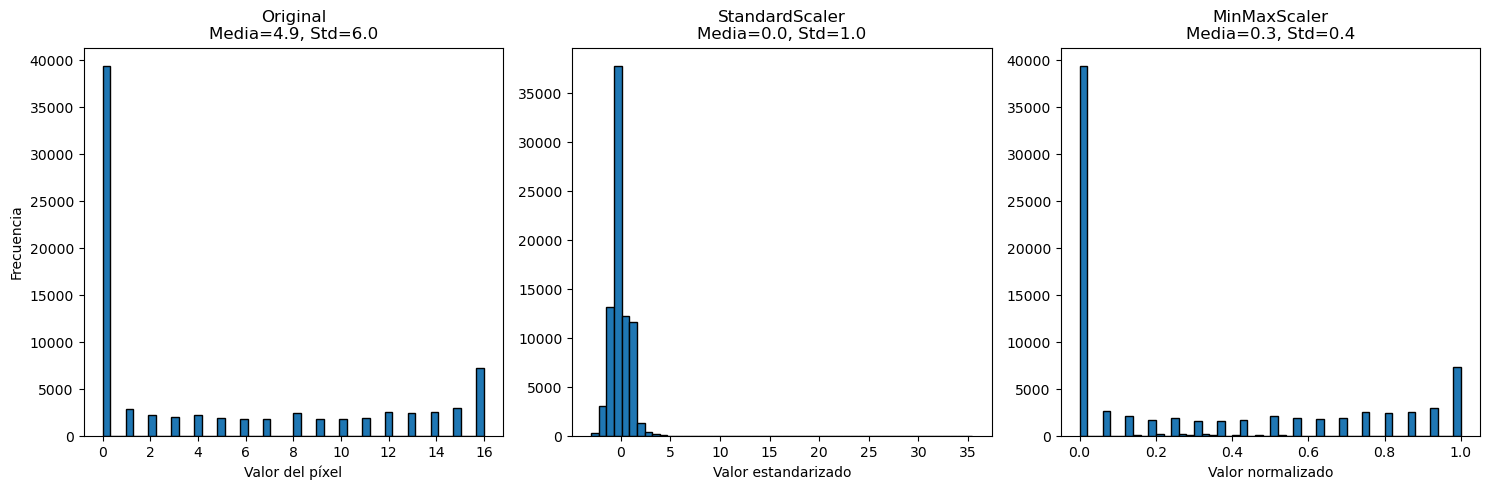

In [8]:
# Tarea 5: Visualizar el efecto del escalado

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Histograma original
axes[0].hist(X_train.flatten(), bins=50, edgecolor='black')
axes[0].set_title(f'Original\nMedia={X_train.mean():.1f}, Std={X_train.std():.1f}')
axes[0].set_xlabel('Valor del píxel')
axes[0].set_ylabel('Frecuencia')

# Histograma StandardScaler
axes[1].hist(X_train_std.flatten(), bins=50, edgecolor='black')
axes[1].set_title(f'StandardScaler\nMedia={X_train_std.mean():.1f}, Std={X_train_std.std():.1f}')
axes[1].set_xlabel('Valor estandarizado')

# Histograma MinMaxScaler
axes[2].hist(X_train_mm.flatten(), bins=50, edgecolor='black')
axes[2].set_title(f'MinMaxScaler\nMedia={X_train_mm.mean():.1f}, Std={X_train_mm.std():.1f}')
axes[2].set_xlabel('Valor normalizado')

plt.tight_layout()
plt.show()

¿De dónde salen los ~40.000?
Como las imágenes son dígitos pequeños (8 × 8) dibujados en el centro de la imagen:

La inmensa mayoría del espacio de alrededor es fondo negro (valor 0).
De los 80.448 píxeles del conjunto de entrenamiento (1257 imágenes × 64), aproximadamente la mitad (39.341, el 49 %) valen exactamente 0.
El histograma simplemente ha contado:

"¿Cuántos píxeles en total valen 0?" → 39.341 píxeles (la barra gigante del 0).
"¿Cuántos píxeles valen 1?" → 2.867 píxeles.
"¿Cuántos píxeles valen 16?" → 7.302 píxeles.


Gráfico Original: Muestra tus datos reales sin tocar (rango 0 a 16). Revela que la inmensa mayoría de los píxeles (~40.000) son fondo negro (valor 0).

StandardScaler: Re-centra los datos alrededor de la media 0.0 (los píxeles negros pasan a ser alrededor de −0.8). Muestra que el modelo manejará valores negativos y positivos, pero genera una cola muy larga hacia la derecha (≈35) debido a píxeles con varianza casi nula en los bordes.

MinMaxScaler: Comprime todos los datos exactamente al rango [0.0,1.0], conservando la misma forma exacta que la distribución original. Ningún valor se dispara.

### Análisis de Outliers

EFECTO DE OUTLIERS EN ESCALADORES

Outliers creados en posiciones: [ 435  101   51   63 1072  423 1035  585 1223 1036]

Original con outliers:
  Media: 5.24, Std: 8.88

StandardScaler:
  Media: 0.00, Std: 0.97
  Rango: [-1.30, 35.44]

MinMaxScaler:
  Media: 0.04, Std: 0.07
  Rango: [0.00, 1.00]


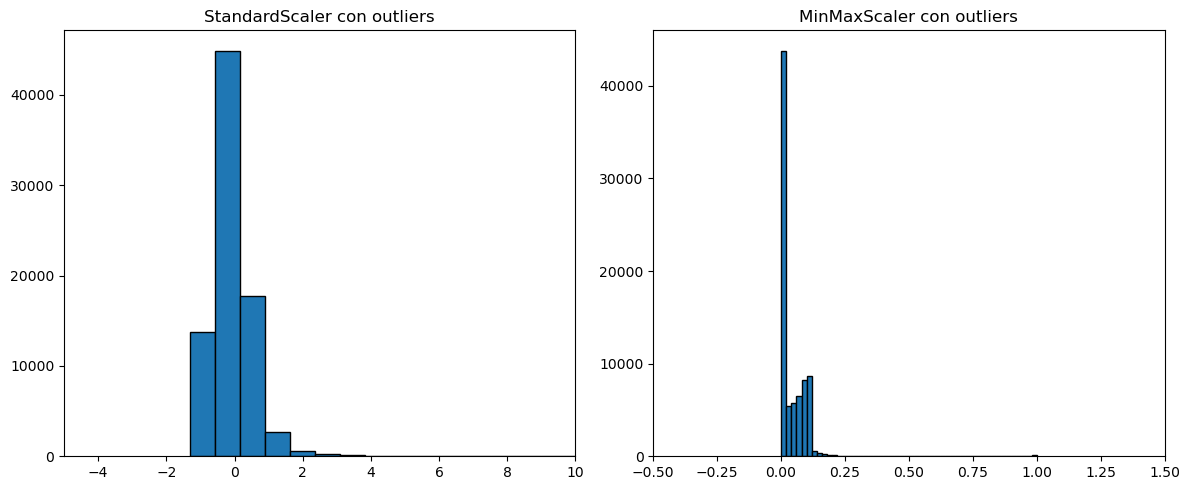

In [9]:
# Tarea 6: Analizar efecto de outliers

# Crear datos con outliers artificiales
np.random.seed(42)
X_con_outliers = X_train.copy()
outlier_indices = np.random.choice(len(X_train), 10, replace=False)
X_con_outliers[outlier_indices] = X_con_outliers[outlier_indices] * 10

# Aplicar escaladores
scaler_std_out = StandardScaler()
scaler_mm_out = MinMaxScaler()

X_outliers_std = scaler_std_out.fit_transform(X_con_outliers)
X_outliers_mm = scaler_mm_out.fit_transform(X_con_outliers)

print("EFECTO DE OUTLIERS EN ESCALADORES")
print("=" * 60)
print(f"\nOutliers creados en posiciones: {outlier_indices}")
print("\nOriginal con outliers:")
print(f"  Media: {X_con_outliers.mean():.2f}, Std: {X_con_outliers.std():.2f}")

print("\nStandardScaler:")
print(f"  Media: {X_outliers_std.mean():.2f}, Std: {X_outliers_std.std():.2f}")
print(f"  Rango: [{X_outliers_std.min():.2f}, {X_outliers_std.max():.2f}]")

print("\nMinMaxScaler:")
print(f"  Media: {X_outliers_mm.mean():.2f}, Std: {X_outliers_mm.std():.2f}")
print(f"  Rango: [{X_outliers_mm.min():.2f}, {X_outliers_mm.max():.2f}]")

# Visualizar
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(X_outliers_std.flatten(), bins=50, edgecolor='black')
axes[0].set_title('StandardScaler con outliers')
axes[0].set_xlim(-5, 10)

axes[1].hist(X_outliers_mm.flatten(), bins=50, edgecolor='black')
axes[1].set_title('MinMaxScaler con outliers')
axes[1].set_xlim(-0.5, 1.5)

plt.tight_layout()
plt.show()

⚠️ Efecto de los outliers en MinMaxScaler:
Antes (Sin outliers):

Media: 0.31, Std: 0.38
Tus datos estaban distribuidos de forma rica y variada a lo largo de todo el rango [0.0,1.0].
Después (Con outliers):

Media: 0.04, Std: 0.07
¿Qué significa esto? Que la gran mayoría de los datos pasan a valer casi cero.
Como el nuevo máximo es 160, el valor 16.0 (que antes era el máximo 1.0) ahora se transforma en 16/160=0.10.

Conclusión: Solo 10 imágenes con outliers han hecho que todas las demás imágenes normales queden aplastadas entre 0.00 y 0.10, perdiendo contraste e información útil para el modelo.

🛡️ Cómo reaccionó StandardScaler:
Antes: Rango [-2.97, 35.44], Media 0.00, Std 0.97
Después: Rango [-1.30, 35.44], Media 0.00, Std 0.97

¿Qué significa esto?
La media se mantiene en 0.00 y la desviación en 0.97.
Aunque el rango se ha comprimido un poco, las imágenes normales no se han "deformado" ni aplastado a un rincón como en MinMaxScaler. Mantienen su escala centrada en torno a la media de forma mucho más estable.


**Preguntas para Responder**
1. ¿Por qué es importante hacer `fit_transform()` solo en train? porque fit aprende las estadisticas de entrenamiento (media,desviacion) y transform aplica la formula para aplicar las medias y desviaciones ( x - media / desviacion). Si hicieramos fit en los test sufririamos un data leakage, que seria como hacer trampas, porque aprenderia informacion o estadisticas del conjunto de test
2. ¿Qué escalador es más sensible a outliers? MinMaxScalers. Un valor anomalo extremo comprime y aplasta a todos los demas valores normales
3. ¿En qué afecta la elección del escalador al rendimiento del modelo? Dado que minmax es mucho mas sensible a los outliers, eso afecta a la resolucion de valores ya que si hay un outlier muy claro un resultado en un rango normal se veria minimizado a niveles exagerados pudiendo hablar de un 50% de diferencia entre ambos posibles resultados. Lo cual no afectaria en el StandardScaler porque sus parametros de media y desviacion para devolver los valores.

---
## 📝 Ejercicio 4: Transformación de Variables

### Objetivo
Aplicar One-Hot Encoding y analizar su importancia para la clasificación.

### Tarea
Convertir las etiquetas a formato One-Hot y analizar el impacto.

In [10]:
# Cargar datos
digits = load_digits()
X = digits.images.reshape((len(digits.images), -1))
y = digits.target

print("=" * 60)
print("TRANSFORMACIÓN DE VARIABLES")
print("=" * 60)
print(f"Etiquetas originales: {y[:20]}")
print(f"Shape de y: {y.shape}")
print(f"Clases únicas: {np.unique(y)}")

TRANSFORMACIÓN DE VARIABLES
Etiquetas originales: [0 1 2 3 4 5 6 7 8 9 0 1 2 3 4 5 6 7 8 9]
Shape de y: (1797,)
Clases únicas: [0 1 2 3 4 5 6 7 8 9]


### Ejercicio Práctico

In [11]:
# Tarea 7: One-Hot Encoding con np.eye()

# Método 1: Usando np.eye() (como vimos en clase)
num_clases = len(np.unique(y))
Y_onehot = np.eye(num_clases)[y] # Recordatorio: crea array de ceros menos un 1 y reemplaza los valores a traves de la key

print("ONE-HOT ENCODING CON np.eye()")
print("=" * 60)
print(f"\nEtiquetas originales: {y[:10]}")
print("\nEtiquetas One-Hot:")
print(Y_onehot[:10])
print(f"\nShape de Y_onehot: {Y_onehot.shape}")

# Verificar equivalencia
print("\nVerificación:")
for i in range(5):
    print(f"y[{i}] = {y[i]} → One-Hot = {Y_onehot[i]}")

ONE-HOT ENCODING CON np.eye()

Etiquetas originales: [0 1 2 3 4 5 6 7 8 9]

Etiquetas One-Hot:
[[1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]]

Shape de Y_onehot: (1797, 10)

Verificación:
y[0] = 0 → One-Hot = [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
y[1] = 1 → One-Hot = [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
y[2] = 2 → One-Hot = [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
y[3] = 3 → One-Hot = [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
y[4] = 4 → One-Hot = [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]


### Análisis de Errores Comunes

In [12]:
# Tarea 8: Demostrar error común con np.eye()

print("ERROR COMÚN: dimensiones incorrectas")
print("=" * 60)

# Error: usar np.eye(2) cuando hay 10 clases
try:
    Y_wrong = np.eye(2)[y]  # Esto debería fallar
    print("No se produjo error (inesperado)")
except IndexError as e:
    print(f"Error producido: {e}")
    print("Solución: usar np.eye(num_clases) donde num_clases = 10")

# Solución correcta
Y_correct = np.eye(num_clases)[y]
print(f"\nSolución correcta: np.eye({num_clases})")
print(f"Shape resultante: {Y_correct.shape}")

ERROR COMÚN: dimensiones incorrectas
Error producido: index 2 is out of bounds for axis 0 with size 2
Solución: usar np.eye(num_clases) donde num_clases = 10

Solución correcta: np.eye(10)
Shape resultante: (1797, 10)


### Comparación con scikit-learn

In [13]:
# Tarea 9: Comparar con OneHotEncoder de scikit-learn
from sklearn.preprocessing import OneHotEncoder

# Método 2: Usando OneHotEncoder
encoder = OneHotEncoder(sparse_output=False)
Y_sklearn = encoder.fit_transform(y.reshape(-1, 1))

print("COMPARACIÓN DE MÉTODOS")
print("=" * 60)
print("\nMétodo np.eye():")
print(f"  Shape: {Y_onehot.shape}")
print(f"  Tipo: {type(Y_onehot)}")

print("\nMétodo OneHotEncoder:")
print(f"  Shape: {Y_sklearn.shape}")
print(f"  Tipo: {type(Y_sklearn)}")

print(f"\n¿Son equivalentes? {np.allclose(Y_onehot, Y_sklearn)}")

COMPARACIÓN DE MÉTODOS

Método np.eye():
  Shape: (1797, 10)
  Tipo: <class 'numpy.ndarray'>

Método OneHotEncoder:
  Shape: (1797, 10)
  Tipo: <class 'numpy.ndarray'>

¿Son equivalentes? True


Usa np.eye() para prototipado rápido o scripts sencillos donde sabes que las clases son 100% numéricas, continuas y fijas (como en este caso, dígitos del 0 al 9).

Usa OneHotEncoder para código de producción y proyectos reales donde usas Pipelines, trabajas con variables categóricas (texto) y necesitas que el código sea robusto ante datos desconocidos.

### Análisis de Impacto

In [14]:
# Tarea 10: Analizar impacto en el entrenamiento

from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import OneHotEncoder

# Dividir datos
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# 1. Crear el encoder
# sparse_output=False es para que devuelva un array normal (como np.eye)
encoder = OneHotEncoder(sparse_output=False)

# 2. Scikit-learn exige que la entrada sea 2D, por eso hacemos .reshape(-1, 1)
# Hacemos fit_transform SÓLO en train
Y_train_onehot_scklearn = encoder.fit_transform(y_train.reshape(-1, 1))

# 3. Hacemos solo transform en test (usando las reglas que aprendió en train)
Y_test_onehot_scklearn = encoder.transform(y_test.reshape(-1, 1))


# One-Hot para entrenamiento
Y_train_onehot = np.eye(num_clases)[y_train]
Y_test_onehot = np.eye(num_clases)[y_test]

# Entrenar con etiquetas originales
clf1 = MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, random_state=42)
clf1.fit(X_train, y_train)
score1 = clf1.score(X_test, y_test)

# Entrenar con One-Hot
clf2 = MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, random_state=42)
clf2.fit(X_train, Y_train_onehot)
score2 = clf2.score(X_test, Y_test_onehot)

print("IMPACTO DEL ONE-HOT ENCODING")
print("=" * 60)
print(f"\nCon etiquetas originales: {score1:.4f}")
print(f"Con One-Hot Encoding: {score2:.4f}")
print("\nNota: con y entero, MLPClassifier hace el one-hot internamente (problema multiclase, softmax).")
print("Con una matriz one-hot, sklearn lo interpreta como problema MULTILABEL (sigmoide por clase),")
print("y score() devuelve la subset accuracy, así que ambos valores no son estrictamente comparables.")

IMPACTO DEL ONE-HOT ENCODING

Con etiquetas originales: 0.9667
Con One-Hot Encoding: 0.9444

Nota: con y entero, MLPClassifier hace el one-hot internamente (problema multiclase, softmax).
Con una matriz one-hot, sklearn lo interpreta como problema MULTILABEL (sigmoide por clase),
y score() devuelve la subset accuracy, así que ambos valores no son estrictamente comparables.


**Preguntas para Responder**
1. ¿Por qué One-Hot Encoding es útil para redes neuronales? Porque ayuda a clasificar en rango 0 o 1 los valores dados, el cual nos ayuda a identificiar la neurona a encender

2. ¿Qué problema resuelve el One-Hot Encoding?  Elimina el problema de la "falsa ordinalidad" (relación de orden o magnitud). Evita que el modelo asuma matemáticamente que una clase vale más que otra (ej. asumir que la clase 3 es mayor que la clase 1), transformándolas en columnas independientes donde todas están a la misma "distancia" y tienen la misma importancia.

3. ¿En qué casos NO es necesario usar One-Hot Encoding? Cuando se usan librerias de alto nivel como Scickit, o cuando la variable si tiene orden real (bajo,medio.alto)

---
## 📝 Ejercicio 5: Reducción de Dimensionalidad

### Objetivo
Comparar diferentes técnicas de reducción de dimensionalidad.

### Tarea
Aplicar PCA, t-SNE y comparar resultados.

In [15]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# Preparar datos
X_flat = digits.images.reshape((len(digits.images), -1))
y = digits.target

# Estandarizar (importante para PCA)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_flat)

print("=" * 60)
print("REDUCCIÓN DE DIMENSIONALIDAD")
print("=" * 60)
print(f"Dimensiones originales: {X_scaled.shape[1]}")

REDUCCIÓN DE DIMENSIONALIDAD
Dimensiones originales: 64


### Ejercicio Práctico: PCA

PCA - 2 Componentes
Shape original: (1797, 64)
Shape reducido: (1797, 2)

Varianza explicada por componente:
  PC1: 12.03%
  PC2: 9.56%
  Total: 21.59%


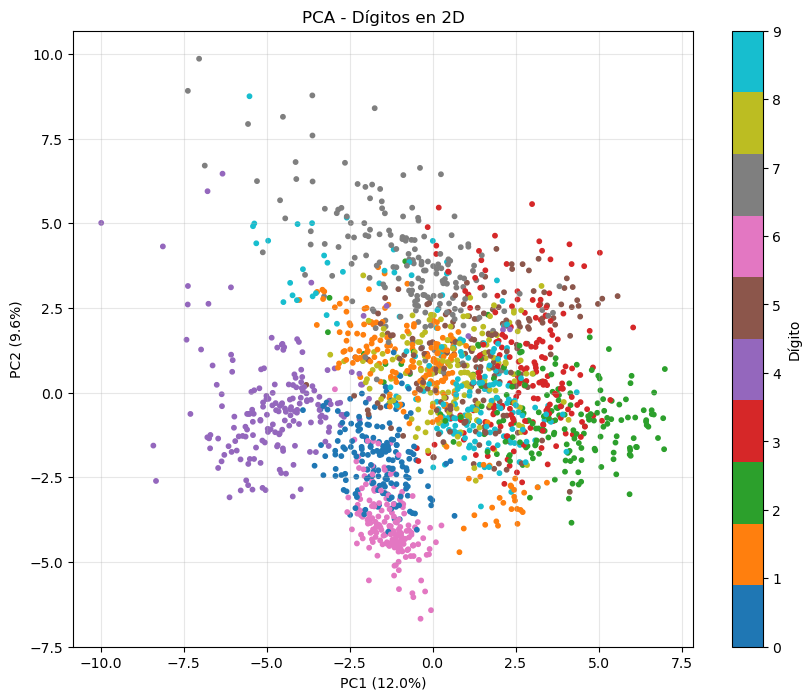

In [16]:
# Tarea 11: Aplicar PCA

# PCA a 2 componentes
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

print("PCA - 2 Componentes")
print("=" * 60)
print(f"Shape original: {X_scaled.shape}")
print(f"Shape reducido: {X_pca_2d.shape}")
print("\nVarianza explicada por componente:")
print(f"  PC1: {pca_2d.explained_variance_ratio_[0]*100:.2f}%")
print(f"  PC2: {pca_2d.explained_variance_ratio_[1]*100:.2f}%")
print(f"  Total: {sum(pca_2d.explained_variance_ratio_)*100:.2f}%")

# Visualizar
plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=y, cmap='tab10', s=10)
plt.colorbar(scatter, label='Dígito')
plt.xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('PCA - Dígitos en 2D')
plt.grid(True, alpha=0.3)
plt.show()

¿Qué es exactamente PC1?
El PC1 (Primer Componente Principal) es la dirección o eje donde los datos tienen mayor variación.
En imágenes, ¿qué suele significar físicamente el PC1? Suele capturar el cambio más gordo o más radical de todo el dataset. Por ejemplo, podría darse cuenta de que la mayor diferencia entre unos dígitos y otros es "cuánta tinta hay en el centro vertical de la imagen"

¿Qué es exactamente PC2?
El PC2 (Segundo Componente Principal) es el segundo eje más importante. Tiene dos reglas estrictas:

Tiene que ser perpendicular (ortogonal) al PC1 (no puede estar correlacionado con él; no puede medir la misma cosa).
De todas las opciones perpendiculares posibles, es la que captura la segunda mayor cantidad de variación.
Siguiendo el ejemplo anterior, si PC1 midió "tinta en el centro vertical", PC2 podría estar midiendo (mediante otra mezcla de los 64 píxeles) "cuánta tinta hay en la parte superior e inferior" (lo que ayuda a distinguir un '3' de un '8' o un '9').

1. La cantidad de información retenida (Ejes)
Eje X (PC1): Retiene el 12.0% de la varianza total (de la información) de las imágenes originales.
Eje Y (PC2): Retiene el 9.6% de la varianza.
Total: Estamos viendo solo el 21.6% de la información total que había en los 64 píxeles. El ~78% restante de los detalles se ha perdido al aplastarlo a 2 dimensiones. ¡Por eso los puntos están tan revueltos y solapados en el centro!
2. Lo que SÍ ha logrado separar bien (Las agrupaciones claras)
A pesar de perder tanta información, hay dígitos que PCA ha logrado aislar muy bien:

Dígito 0 (Azul oscuro, abajo a la izquierda): Fíjate cómo todos los puntos azul oscuro forman una "isla" muy compacta en las coordenadas (-2, -3). Significa que los ceros tienen un patrón de píxeles muy único y consistente que PC1 y PC2 detectan fácilmente.
Dígito 4 (Morado, a la izquierda): Los cuatros forman otra nube clara alrededor de (-5, 0).
Dígito 6 (Rosa, abajo): Se agrupan muy bien alrededor de (-1, -4).
3. El caos central (Lo que NO ha logrado separar)
Si miras el centro del gráfico (alrededor de las coordenadas (0, 0) y (2, 2)), es una sopa de colores: rojo (3), verde (2), marrón (5), amarillo verdoso (8) y cian (9).
¿Qué significa esto? Que usando solo estos dos componentes principales (solo un 21.6% de la información), el dígito '3', el '8', el '5' y el '9' se parecen demasiado entre sí.
Esto tiene sentido biológico/visual: un '3', un '8' y un '9' comparten muchísimos píxeles en común (curvas superiores e inferiores, zonas medias entrelazadas). El PCA necesitaría mirar el PC3, PC4 o PC5 para encontrar las sutiles diferencias (los "huecos" del 8 vs los "bordes abiertos" del 3) que permitan separarlos.

Resumen para el desarrollador:
Esta gráfica demuestra que PCA es rápido y útil para una inspección general, pero que 2 dimensiones no son suficientes para clasificar correctamente los 10 dígitos (porque hay demasiado solapamiento en el centro). Por eso, en la Tarea 12 del cuaderno verás que se necesita subir a unas 20 o 30 componentes para retener el 95% de la varianza y que un modelo (como el MLP) pueda separar bien el '3' del '8'.

### Ejercicio Práctico: Análisis de Componentes

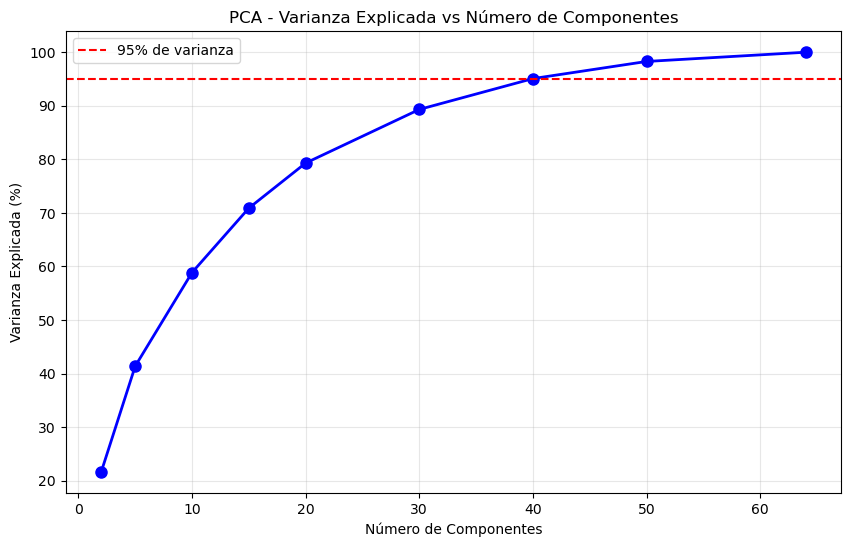


Número de componentes para 95% de varianza: 40


In [17]:
# Tarea 12: Analizar cuántos componentes necesitamos

# Probar con diferentes números de componentes
n_components_range = [2, 5, 10, 15, 20, 30, 40, 50, 64]
variance_explained = []

for n in n_components_range:
    pca = PCA(n_components=n)
    pca.fit(X_scaled)
    variance_explained.append(sum(pca.explained_variance_ratio_) * 100) # porcentaje de informacion que ha logrado salvar

# Visualizar
plt.figure(figsize=(10, 6))
plt.plot(n_components_range, variance_explained, 'bo-', linewidth=2, markersize=8)
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Explicada (%)')
plt.title('PCA - Varianza Explicada vs Número de Componentes')
plt.grid(True, alpha=0.3)
plt.axhline(y=95, color='r', linestyle='--', label='95% de varianza')
plt.legend()
plt.show()

# Encontrar número mínimo para 95% de varianza
pca_full = PCA()
pca_full.fit(X_scaled)
cumsum = np.cumsum(pca_full.explained_variance_ratio_) # cumsum es un acumulador es decir : 1 , 1+ 2, 1+2+3
n_95 = np.argmax(cumsum >= 0.95) + 1
print(f"\nNúmero de componentes para 95% de varianza: {n_95}")

### Ejercicio Práctico: t-SNE

t-SNE - 2 Componentes
Shape original: (1000, 64)
Shape reducido: (1000, 2)


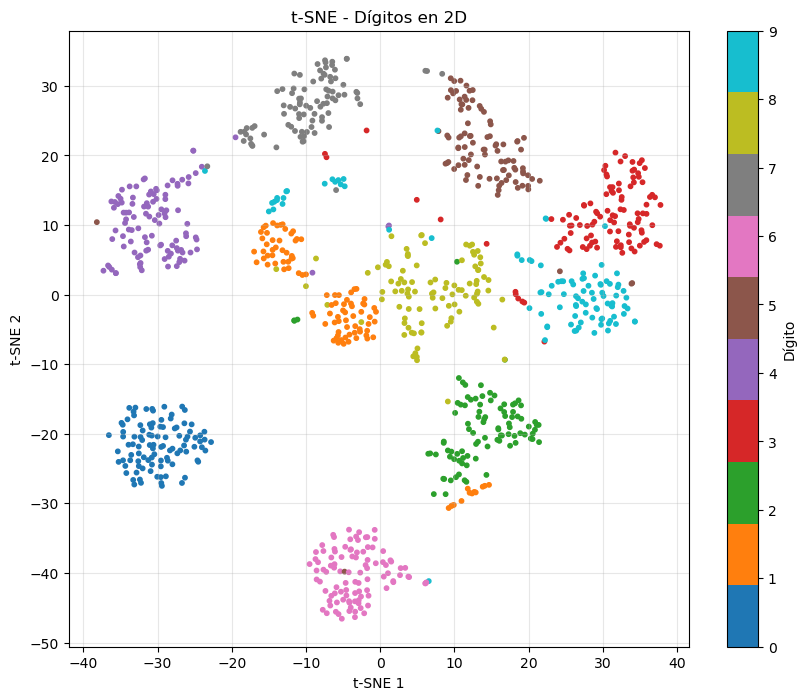

In [18]:
# Tarea 13: Aplicar t-SNE

# t-SNE es más lento, usar submuestra si es necesario
n_samples = 1000
rng = np.random.default_rng(42)  # semilla local para que el resultado sea reproducible
indices = rng.choice(len(X_scaled), n_samples, replace=False)
X_subset = X_scaled[indices]
y_subset = y[indices]

# Aplicar t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30) # perplexity: mirar vecinos mas inmediato, por defecto suele ser 30
X_tsne = tsne.fit_transform(X_subset)

print("t-SNE - 2 Componentes")
print("=" * 60)
print(f"Shape original: {X_subset.shape}")
print(f"Shape reducido: {X_tsne.shape}")

# Visualizar
plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_subset, cmap='tab10', s=10)
plt.colorbar(scatter, label='Dígito')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.title('t-SNE - Dígitos en 2D')
plt.grid(True, alpha=0.3)
plt.show()

Resumen para el desarrollador:

PCA nos dio una visión general pero mezclaba clases complejas (solo útil para compresión, malo para visualizar).
t-SNE desenreda los datos no lineales. Es la herramienta definitiva para ver si tu dataset tiene estructura natural (clases separables). Si ves un gráfico como este, significa que el problema es "fácil" de aprender para un modelo neuronal, porque las clases ya forman grupos naturales en el espacio de características.

### Comparación PCA vs t-SNE

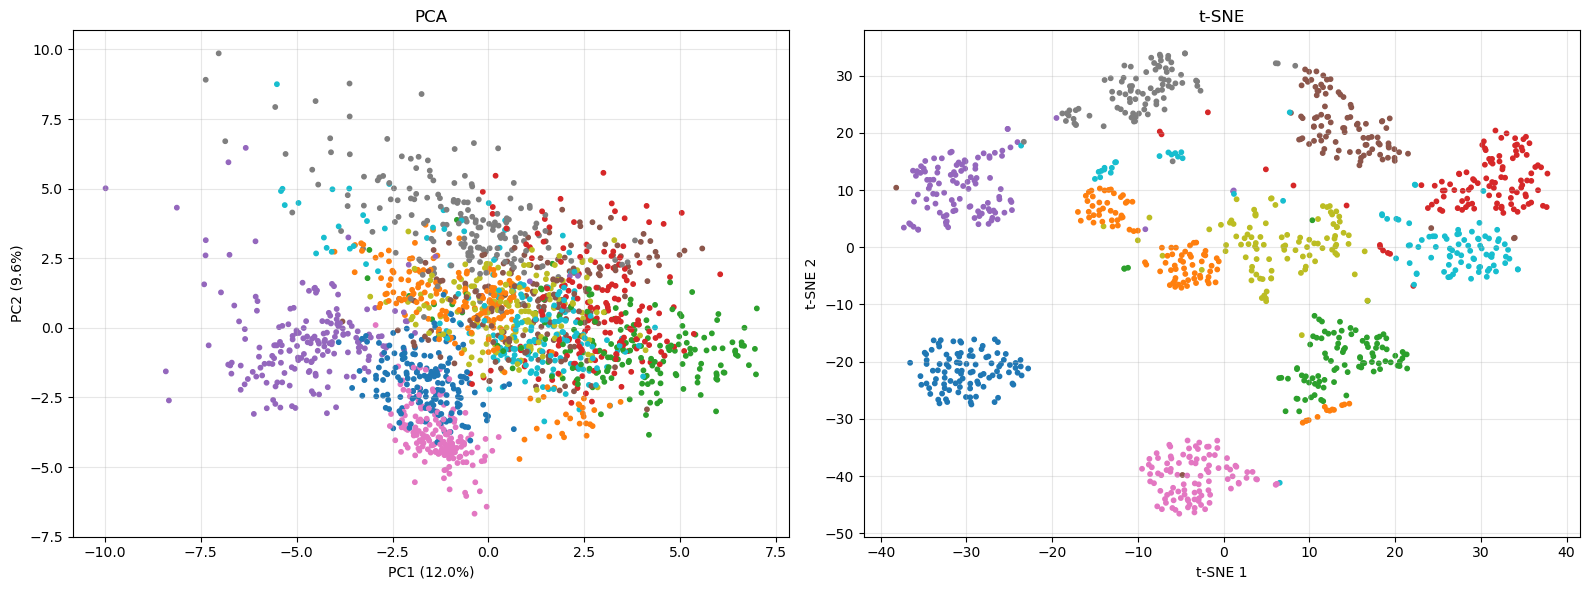

COMPARACIÓN PCA vs t-SNE

PCA:
  ✓ Rápido
  ✓ Reproducible
  ✓ Preserva varianza global
  ✗ Solo captura relaciones lineales
  ✗ Pierde estructura local

t-SNE:
  ✓ Preserva estructura local
  ✓ Captura relaciones no lineales
  ✓ Mejor visualización
  ✗ Lento
  ✗ Estocástico: depende de random_state y de la perplexity
  ✗ No preserva distancias globales


In [19]:
# Tarea 14: Comparar PCA vs t-SNE

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# PCA
axes[0].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=y, cmap='tab10', s=10)
axes[0].set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)')
axes[0].set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)')
axes[0].set_title('PCA')
axes[0].grid(True, alpha=0.3)

# t-SNE
axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_subset, cmap='tab10', s=10)
axes[1].set_xlabel('t-SNE 1')
axes[1].set_ylabel('t-SNE 2')
axes[1].set_title('t-SNE')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("COMPARACIÓN PCA vs t-SNE")
print("=" * 60)
print("\nPCA:")
print("  ✓ Rápido")
print("  ✓ Reproducible")
print("  ✓ Preserva varianza global")
print("  ✗ Solo captura relaciones lineales")
print("  ✗ Pierde estructura local")

print("\nt-SNE:")
print("  ✓ Preserva estructura local")
print("  ✓ Captura relaciones no lineales")
print("  ✓ Mejor visualización")
print("  ✗ Lento")
print("  ✗ Estocástico: depende de random_state y de la perplexity")
print("  ✗ No preserva distancias globales")

**Preguntas para Responder**
1. ¿Por qué es importante estandarizar antes de PCA? Porque PCA busca las direcciones de "mayor varianza" (mayor diferencia o extensión) en los datos. Si no estandarizamos (por ejemplo, si un píxel se mide de 0 a 1000 y otro de 0 a 1), PCA creerá erróneamente que el píxel de valores grandes es el más importante solo por su escala matemática. Estandarizar (StandardScaler) pone a todas las variables a competir en igualdad de condiciones (media 0, varianza 1) para que PCA encuentre los patrones estructurales reales, no los sesgos de escala.

2. ¿Cuándo usar PCA vs t-SNE? Usamos PCA como paso de preprocesamiento (dentro de un Pipeline) para comprimir los datos y reducir el ruido antes de entrenar un modelo, ya que es computacionalmente muy rápido y preserva distancias matemáticas globales.
Usamos t-SNE exclusivamente para visualización de datos complejos en 2D/3D, ya que agrupa las clases mucho mejor de forma visual, pero es demasiado lento para usarse como paso de entrenamiento en grandes volúmenes de datos y no preserva distancias matemáticas globales.

3. ¿Qué significa "varianza explicada"? Es el porcentaje de la información total (o variación) original de los datos que un componente principal logra retener después de la compresión.

Usa t-SNE SOLO para VISUALIZAR:

✅ Pros: Es muy adecuado para hacer gráficos en 2D o 3D. Separa muy bien los clústeres y permite entender si tus datos tienen patrones claros. ❌ Contras:

Es lento de calcular.

No sirve para comprimir datos antes de entrenar un modelo. Sus coordenadas matemáticas (t-SNE 1 y t-SNE 2) no tienen un significado global real, solo sirven para la visualización.

Usa PCA para PREPROCESAR Y ENTRENAR:

✅ Pros: Es muy rápido de calcular. Puedes usarlo para reducir tus 64 píxeles a 20 columnas y meter esas 20 columnas a tu Red Neuronal (MLP) para que entrene más rápido y mejor, sin perder la información matemática real (varianza). ❌ Contras: Es poco adecuado para visualizar en 2D si las relaciones entre los datos son complejas (como viste, solapa los colores en el centro).

Resumen del Desarrollador: Usa t-SNE para el gráfico del informe, ya que muestra con claridad cómo se separan los números. Usa PCA en el código del Pipeline para comprimir los datos antes de dárselos al algoritmo de clasificación. (Es justo lo que hace el Ejercicio 7 de este notebook).

---
## 📝 Ejercicio 6: Modelos de Clasificación

### Objetivo
Entrenar y evaluar un MLPClassifier, comparando diferentes configuraciones.

### Tarea
Implementar un pipeline completo de clasificación.

In [20]:
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

# Preparar datos
X_flat = digits.images.reshape((len(digits.images), -1))
y = digits.target

# Dividir datos
X_train, X_test, y_train, y_test = train_test_split(
    X_flat, y, test_size=0.3, random_state=42, stratify=y
)

# Estandarizar
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("=" * 60)
print("MODELOS DE CLASIFICACIÓN")
print("=" * 60)
print(f"Train: {X_train_scaled.shape[0]} muestras")
print(f"Test: {X_test_scaled.shape[0]} muestras")

MODELOS DE CLASIFICACIÓN
Train: 1257 muestras
Test: 540 muestras


### Ejercicio Práctico: MLP Básico

In [21]:
# Tarea 15: Entrenar MLP básico

# Configuración básica
mlp_basic = MLPClassifier(
    hidden_layer_sizes=(100,),
    max_iter=500,
    random_state=42,
    verbose=False # Es el interruptor para ver u ocultar los logs de entrenamiento de la red neuronal
)

# Entrenar
mlp_basic.fit(X_train_scaled, y_train)

# Evaluar
train_score = mlp_basic.score(X_train_scaled, y_train)
test_score = mlp_basic.score(X_test_scaled, y_test)

print("MLP BÁSICO - 1 capa de 100 neuronas")
print("=" * 60)
print(f"Train Accuracy: {train_score:.4f}")
print(f"Test Accuracy: {test_score:.4f}")
print(f"Diferencia: {train_score - test_score:.4f}")

# Análisis de overfitting
if train_score - test_score > 0.1:
    print("\n⚠️  Posible OVERFITTING detectado")
elif train_score < 0.9:
    print("\n⚠️  Posible UNDERFITTING detectado")
else:
    print("\n✓  Modelo bien ajustado")

MLP BÁSICO - 1 capa de 100 neuronas
Train Accuracy: 1.0000
Test Accuracy: 0.9796
Diferencia: 0.0204

✓  Modelo bien ajustado


### Ejercicio Práctico: Comparar Arquitecturas

Arquitectura (50,):
  Train: 1.0000, Test: 0.9741, Params: 3760


Arquitectura (100,):
  Train: 1.0000, Test: 0.9796, Params: 7510


Arquitectura (100, 100):
  Train: 1.0000, Test: 0.9759, Params: 17610


Arquitectura (100, 100, 100):
  Train: 1.0000, Test: 0.9796, Params: 27710


Arquitectura (200, 100, 50):
  Train: 1.0000, Test: 0.9815, Params: 38660


Arquitectura (50, 50, 50, 50):
  Train: 1.0000, Test: 0.9685, Params: 11410


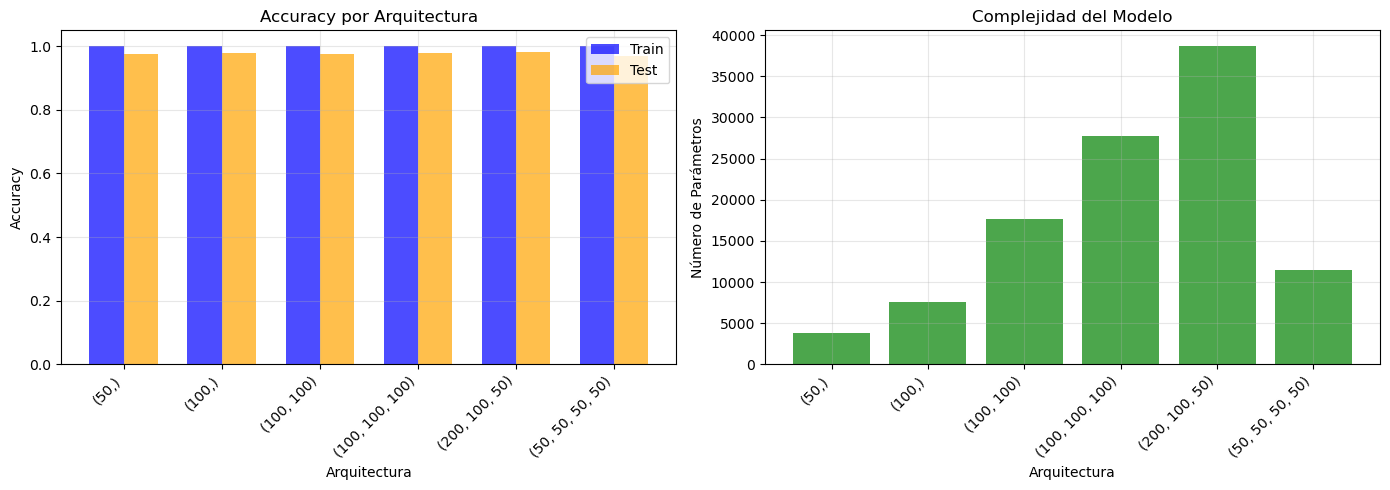

In [22]:
# Tarea 16: Comparar diferentes arquitecturas

architectures = [
    (50,),
    (100,),
    (100, 100),
    (100, 100, 100),
    (200, 100, 50),
    (50, 50, 50, 50)
]

results = []

for arch in architectures:
    mlp = MLPClassifier(
        hidden_layer_sizes=arch,
        max_iter=500,
        random_state=42,
        verbose=False
    )
    mlp.fit(X_train_scaled, y_train)

    train_acc = mlp.score(X_train_scaled, y_train)
    test_acc = mlp.score(X_test_scaled, y_test)
    n_params = sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_) # Cuenta el número total de parámetros entrenables (pesos y sesgos) que tiene la red neuronal.

    results.append({
        'architecture': str(arch),
        'train_acc': train_acc,
        'test_acc': test_acc,
        'n_params': n_params,
        'diff': train_acc - test_acc
    })

    print(f"Arquitectura {arch}:")
    print(f"  Train: {train_acc:.4f}, Test: {test_acc:.4f}, Params: {n_params}")

# Visualizar comparación
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
arch_names = [r['architecture'] for r in results]
train_accs = [r['train_acc'] for r in results]
test_accs = [r['test_acc'] for r in results]

x = range(len(arch_names))
width = 0.35

axes[0].bar([i - width/2 for i in x], train_accs, width, label='Train', color='blue', alpha=0.7)
axes[0].bar([i + width/2 for i in x], test_accs, width, label='Test', color='orange', alpha=0.7)
axes[0].set_xlabel('Arquitectura')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Accuracy por Arquitectura')
axes[0].set_xticks(x)
axes[0].set_xticklabels(arch_names, rotation=45, ha='right')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Número de parámetros
n_params = [r['n_params'] for r in results]
axes[1].bar(x, n_params, color='green', alpha=0.7)
axes[1].set_xlabel('Arquitectura')
axes[1].set_ylabel('Número de Parámetros')
axes[1].set_title('Complejidad del Modelo')
axes[1].set_xticks(x)
axes[1].set_xticklabels(arch_names, rotation=45, ha='right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

💡 La Conclusión Global (El "Insight" del Científico de Datos):

Al cruzar ambos gráficos, la conclusión es contundente: Para este problema específico (clasificar dígitos de 8x8), usar una red neuronal muy grande resulta innecesario.

Aumentar la complejidad de ~4.000 parámetros a casi ~40.000 parámetros (multiplicar por 10 el tamaño del modelo y el tiempo de entrenamiento) no aporta prácticamente ningún beneficio extra en la precisión (accuracy).

Matiz: las diferencias entre arquitecturas (entre 0,5 y 1 punto, unas 3 a 5 imágenes de las 540 de test) están dentro del ruido de un único split y una única semilla.

Decisión de diseño: En un entorno de producción, conviene quedarse con la arquitectura (50,) o a lo sumo la (100,). Entrenará mucho más rápido, ocupará menos memoria RAM, y dará exactamente el mismo buen resultado que las arquitecturas más profundas.

### Ejercicio Práctico: Matriz de Confusión

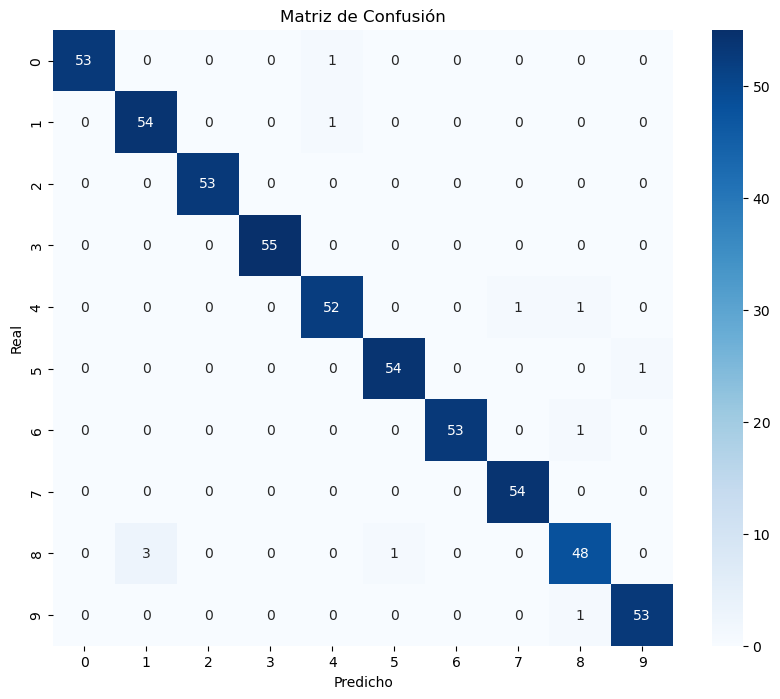

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

           0       1.00      0.98      0.99        54
           1       0.95      0.98      0.96        55
           2       1.00      1.00      1.00        53
           3       1.00      1.00      1.00        55
           4       0.96      0.96      0.96        54
           5       0.98      0.98      0.98        55
           6       1.00      0.98      0.99        54
           7       0.98      1.00      0.99        54
           8       0.94      0.92      0.93        52
           9       0.98      0.98      0.98        54

    accuracy                           0.98       540
   macro avg       0.98      0.98      0.98       540
weighted avg       0.98      0.98      0.98       540



In [23]:
# Tarea 17: Analizar errores con matriz de confusión

# Usar la arquitectura elegida en la conclusión anterior: (100,)
best_mlp = MLPClassifier(
    hidden_layer_sizes=(100,),
    max_iter=500,
    random_state=42,
    verbose=False
)
best_mlp.fit(X_train_scaled, y_train)

# Predecir
y_pred = best_mlp.predict(X_test_scaled)

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.title('Matriz de Confusión')
plt.show()

# Reporte de clasificación
print("REPORTE DE CLASIFICACIÓN")
print("=" * 60)
print(classification_report(y_test, y_pred))

**Preguntas para Responder**
1. ¿Qué arquitectura funciona mejor? ¿Por qué? Una arquitectura 50 o 100. Ya que no gasta muchos parametros y los resultado siguen siendo realmente buenos. Este principio tiene nombre, se llama la "Navaja de Occam" aplicada a ML: "entre dos modelos que dan el mismo resultado, elige siempre el más simple". La arquitectura (100,) es la elección óptima porque ofrece el mejor ratio rendimiento/coste: ~97-98% de accuracy con solo ~7.000 parámetros, frente a los ~40.000 de la arquitectura (200, 100, 50) que no mejora el resultado.
2. ¿Qué dígitos son más difíciles de clasificar? Los 8 y los 1. El 8 es el que más falla (4 errores de 52 en test, el recall más bajo) y 3 de esos errores se predicen como 1, por lo que el 1 recibe clasificaciones erroneas de los 8 y baja su precision.
3. ¿Cómo afecta el número de parámetros al rendimiento? A mayor consumo de parametros mayor uso de Ram, por lo que mas lento se entrena el modelo, o riesgo de overfitting

---
## 📝 Ejercicio 7: Pipeline Completo

### Objetivo
Integrar todas las técnicas en un pipeline profesional.

### Tarea
Crear un pipeline que incluya preprocesamiento, reducción de dimensionalidad y clasificación.

In [24]:
import warnings

from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore', category=ConvergenceWarning)

# Preparar datos
X_flat = digits.images.reshape((len(digits.images), -1))
y = digits.target

# El test se aparta ANTES de la validación cruzada y del grid search
# para que la evaluación final sea realmente sobre datos no vistos.
X_train, X_test, y_train, y_test = train_test_split(
    X_flat, y, test_size=0.3, random_state=42, stratify=y
)

print("=" * 60)
print("PIPELINE COMPLETO DE ML")
print("=" * 60)

# Tarea 18: Crear pipeline
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=50)),
    ('mlp', MLPClassifier(hidden_layer_sizes=(100, 100),
                          max_iter=500,
                          random_state=42))
])

print("Pipeline creado:")
for name, step in pipeline.steps:
    print(f"  {name}: {step}")

# Tarea 19: Validación cruzada
print("\nVALIDACIÓN CRUZADA (5-fold)")
print("=" * 60)

cv_scores = cross_val_score(pipeline, X_train, y_train, cv=5, scoring='accuracy') # El pipeline se entrena y evalúa 5 veces distintas, cada vez usando una parte diferente como test.
print(f"Scores: {cv_scores}")
print(f"Media: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

# Tarea 20: Grid Search para optimizar hiperparámetros
print("\nGRID SEARCH - Optimización de hiperparámetros")
print("=" * 60)

param_grid = {
    'pca__n_components': [20, 40, 50],  # no puede superar las 64 características
    'mlp__hidden_layer_sizes': [(50,), (100,), (100, 100)],
    'mlp__alpha': [0.0001, 0.001, 0.01]
}

grid_search = GridSearchCV( # prueba todas las combinaciones posibles del grid
    pipeline,
    param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print(f"\nMejores parámetros: {grid_search.best_params_}")
print(f"Mejor score: {grid_search.best_score_:.4f}")

PIPELINE COMPLETO DE ML
Pipeline creado:
  scaler: StandardScaler()
  pca: PCA(n_components=50)
  mlp: MLPClassifier(hidden_layer_sizes=(100, 100), max_iter=500, random_state=42)

VALIDACIÓN CRUZADA (5-fold)


Scores: [0.96825397 0.97619048 0.98406375 0.96015936 0.97211155]
Media: 0.9722 (+/- 0.0159)

GRID SEARCH - Optimización de hiperparámetros
Fitting 3 folds for each of 27 candidates, totalling 81 fits



Mejores parámetros: {'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (50,), 'pca__n_components': 50}
Mejor score: 0.9730


La Conclusión General de este Bloque

El pipeline (StandardScaler + PCA + MLP) obtiene un 97,22 % de accuracy media en validación cruzada (5-fold, solo sobre el conjunto de entrenamiento). El Grid Search (3-fold) elige `pca__n_components=50`, `hidden_layer_sizes=(50,)` y `alpha=0.0001` con un 97,30 %, y sobre el test reservado, que no se ha usado en ningún momento de la búsqueda, el resultado es un 97,78 %. Las tres cifras son coherentes con el 97-98 % de las secciones anteriores.

Puntos a tener en cuenta:

- El test se separa **antes** de la validación cruzada y del Grid Search, así que la cifra final es una estimación limpia y no se ha usado para elegir hiperparámetros.
- El PCA con 50 componentes retiene el 98,57 % de la varianza, por lo que apenas se pierde información útil.
- El grid de `pca__n_components` se limita a valores ≤ 64, el número de características. Un valor mayor (por ejemplo 100) hace fallar el ajuste de esas combinaciones.

### Evaluación del Mejor Modelo

EVALUACIÓN DEL MEJOR MODELO
Train Accuracy: 1.0000
Test Accuracy: 0.9778

PCA:
  Componentes: 50
  Varianza explicada: 98.57%


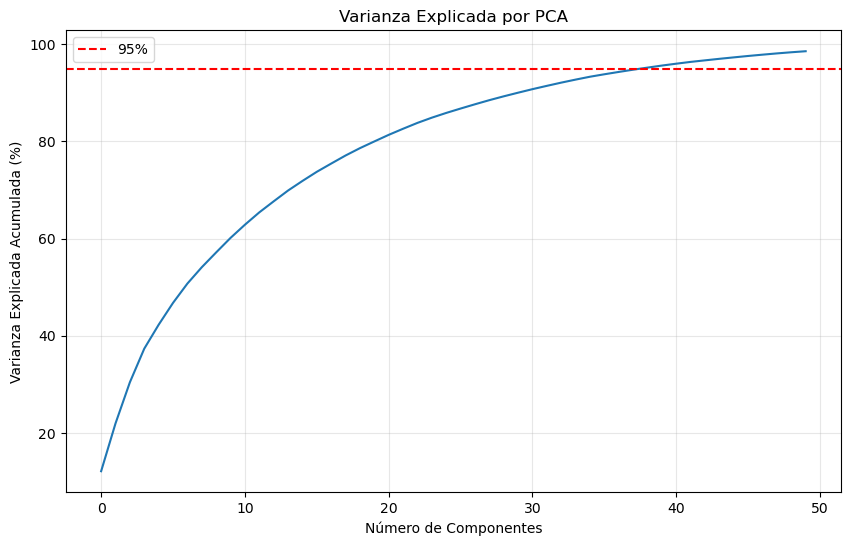

In [25]:
# Tarea 21: Evaluar el mejor modelo

# GridSearchCV ya reentrena el mejor pipeline con todo el train (refit=True)
best_pipeline = grid_search.best_estimator_

# Evaluar
train_score = best_pipeline.score(X_train, y_train)
test_score = best_pipeline.score(X_test, y_test)

print("EVALUACIÓN DEL MEJOR MODELO")
print("=" * 60)
print(f"Train Accuracy: {train_score:.4f}")
print(f"Test Accuracy: {test_score:.4f}")

# Análisis de componentes
pca_step = best_pipeline.named_steps['pca']
print("\nPCA:")
print(f"  Componentes: {pca_step.n_components_}")
print(f"  Varianza explicada: {sum(pca_step.explained_variance_ratio_)*100:.2f}%")

# Visualizar varianza explicada
plt.figure(figsize=(10, 6))
plt.plot(np.cumsum(pca_step.explained_variance_ratio_) * 100)
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Explicada Acumulada (%)')
plt.title('Varianza Explicada por PCA')
plt.grid(True, alpha=0.3)
plt.axhline(y=95, color='r', linestyle='--', label='95%')
plt.legend()
plt.show()

---
## 📝 Ejercicio 8: Comparativa Final

### Objetivo
Comparar diferentes enfoques y documentar pros/contras.

### Tarea
Crear un informe completo de comparación.

COMPARATIVA FINAL DE MODELOS



Logistic Regression:
  Train: 1.0000
  Test: 0.9815
  Overfitting: 0.0185

KNN (k=5):
  Train: 0.9873
  Test: 0.9704
  Overfitting: 0.0169



Random Forest:
  Train: 1.0000
  Test: 0.9685
  Overfitting: 0.0315

SVM:
  Train: 0.9976
  Test: 0.9833
  Overfitting: 0.0143



MLP (1 capa):
  Train: 1.0000
  Test: 0.9796
  Overfitting: 0.0204



MLP (3 capas):
  Train: 1.0000
  Test: 0.9796
  Overfitting: 0.0204

RESUMEN DE RESULTADOS
              Model  Train Accuracy  Test Accuracy  Overfitting
Logistic Regression        1.000000       0.981481     0.018519
          KNN (k=5)        0.987271       0.970370     0.016901
      Random Forest        1.000000       0.968519     0.031481
                SVM        0.997613       0.983333     0.014280
       MLP (1 capa)        1.000000       0.979630     0.020370
      MLP (3 capas)        1.000000       0.979630     0.020370


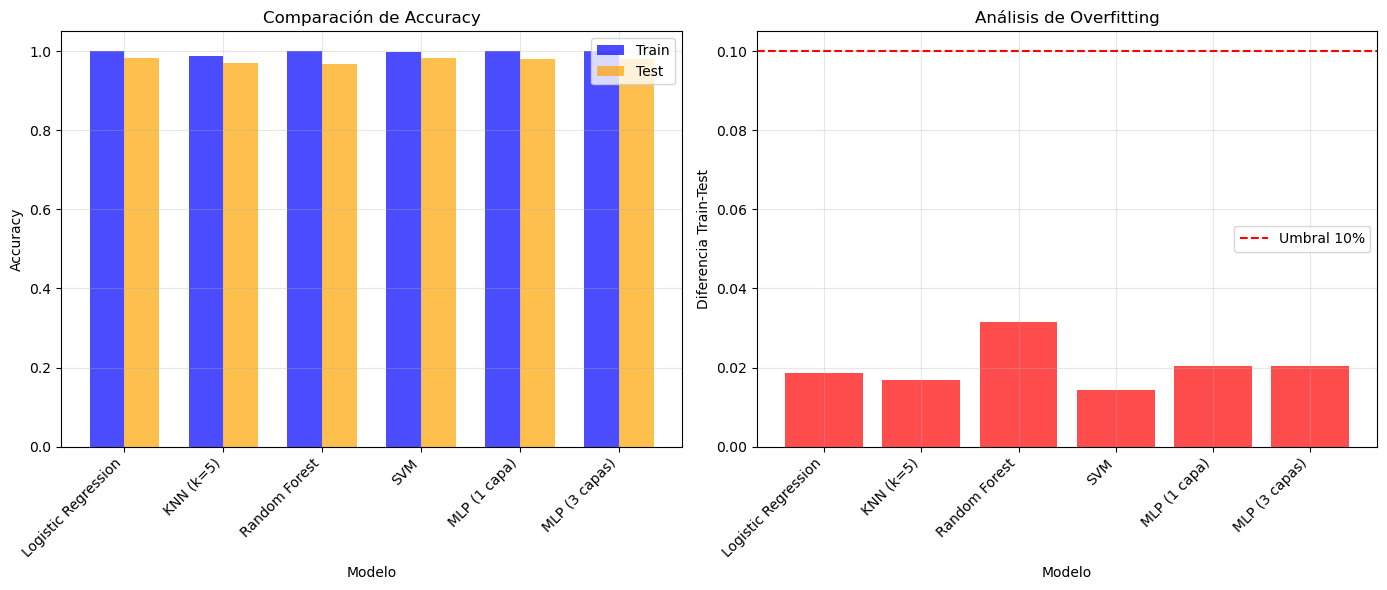

In [26]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

import pandas as pd

# Preparar datos
X_flat = digits.images.reshape((len(digits.images), -1))
y = digits.target

X_train, X_test, y_train, y_test = train_test_split(
    X_flat, y, test_size=0.3, random_state=42, stratify=y
)

# Escalar
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("=" * 60)
print("COMPARATIVA FINAL DE MODELOS")
print("=" * 60)

# Definir modelos
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM': SVC(kernel='rbf', random_state=42),
    'MLP (1 capa)': MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, random_state=42),
    'MLP (3 capas)': MLPClassifier(hidden_layer_sizes=(100, 100, 100), max_iter=500, random_state=42)
}

# Entrenar y evaluar
results = []
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    train_acc = model.score(X_train_scaled, y_train)
    test_acc = model.score(X_test_scaled, y_test)

    results.append({
        'Model': name,
        'Train Accuracy': train_acc,
        'Test Accuracy': test_acc,
        'Overfitting': train_acc - test_acc
    })

    print(f"\n{name}:")
    print(f"  Train: {train_acc:.4f}")
    print(f"  Test: {test_acc:.4f}")
    print(f"  Overfitting: {train_acc - test_acc:.4f}")

# Crear DataFrame de resultados
df_results = pd.DataFrame(results)
print("\n" + "=" * 60)
print("RESUMEN DE RESULTADOS")
print("=" * 60)
print(df_results.to_string(index=False))

# Visualizar
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Accuracy
x = range(len(df_results))
width = 0.35
axes[0].bar([i - width/2 for i in x], df_results['Train Accuracy'],
            width, label='Train', color='blue', alpha=0.7)
axes[0].bar([i + width/2 for i in x], df_results['Test Accuracy'],
            width, label='Test', color='orange', alpha=0.7)
axes[0].set_xlabel('Modelo')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Comparación de Accuracy')
axes[0].set_xticks(x)
axes[0].set_xticklabels(df_results['Model'], rotation=45, ha='right')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Overfitting
axes[1].bar(x, df_results['Overfitting'], color='red', alpha=0.7)
axes[1].set_xlabel('Modelo')
axes[1].set_ylabel('Diferencia Train-Test')
axes[1].set_title('Análisis de Overfitting')
axes[1].set_xticks(x)
axes[1].set_xticklabels(df_results['Model'], rotation=45, ha='right')
axes[1].axhline(y=0.1, color='r', linestyle='--', label='Umbral 10%')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Análisis de Pros y Contras

In [27]:
# Tarea 22: Documentar pros y contras

analisis = """
ANÁLISIS DE PROS Y CONTRAS
==========================

1. LOGISTIC REGRESSION
   ✓ Pros: Rápido, interpretable, buen baseline
   ✗ Contras: Asume linealidad, menos preciso en problemas complejos
   → Uso recomendado: Baseline, datos linealmente separables

2. KNN (k=5)
   ✓ Pros: Simple, no necesita entrenamiento, intuitivo
   ✗ Contras: Lento en predicción, sensible a dimensiones, requiere escalado
   → Uso recomendado: Dataset pequeños, baja dimensionalidad

3. RANDOM FOREST
   ✓ Pros: Robusto, maneja outliers, features mixtas
   ✗ Contras: Menos preciso que deep learning, menos interpretable
   → Uso recomendado: Datos tabulares, baseline sólido

4. SVM
   ✓ Pros: Efectivo en alta dimensionalidad, robusto
   ✗ Contras: Lento con muchos datos, difícil de interpretar
   → Uso recomendado: Alta dimensionalidad, pocos datos

5. MLP (1 capa)
   ✓ Pros: Captura relaciones no lineales, flexible
   ✗ Contras: Requiere más datos, sensible a escalado
   → Uso recomendado: Problemas no lineales, datos suficientes

6. MLP (3 capas)
   ✓ Pros: Mayor capacidad, patrones complejos
   ✗ Contras: Más parámetros, riesgo de overfitting, más lento
   → Uso recomendado: Datos abundantes, problemas complejos
"""

print(analisis)


ANÁLISIS DE PROS Y CONTRAS

1. LOGISTIC REGRESSION
   ✓ Pros: Rápido, interpretable, buen baseline
   ✗ Contras: Asume linealidad, menos preciso en problemas complejos
   → Uso recomendado: Baseline, datos linealmente separables

2. KNN (k=5)
   ✓ Pros: Simple, no necesita entrenamiento, intuitivo
   ✗ Contras: Lento en predicción, sensible a dimensiones, requiere escalado
   → Uso recomendado: Dataset pequeños, baja dimensionalidad

3. RANDOM FOREST
   ✓ Pros: Robusto, maneja outliers, features mixtas
   ✗ Contras: Menos preciso que deep learning, menos interpretable
   → Uso recomendado: Datos tabulares, baseline sólido

4. SVM
   ✓ Pros: Efectivo en alta dimensionalidad, robusto
   ✗ Contras: Lento con muchos datos, difícil de interpretar
   → Uso recomendado: Alta dimensionalidad, pocos datos

5. MLP (1 capa)
   ✓ Pros: Captura relaciones no lineales, flexible
   ✗ Contras: Requiere más datos, sensible a escalado
   → Uso recomendado: Problemas no lineales, datos suficientes

6. M